## 1. Dataset, scenario archive, and paths


In [1]:
import csv
import hashlib
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

DATASET_NAME="alabama"        # Must match sampling notebook
TIME_SLICE="16h"
SCENARIO_PATH_OVERRIDE=None  # Optional absolute .npz path
DATASET_LABEL=DATASET_NAME.replace("_"," ").title()

def find_project_root():
    cwd=Path.cwd().resolve()
    for parent in (cwd,*cwd.parents):
        for candidate in (parent,parent/"GridSFM"):
            if (candidate/"model").is_dir() and (candidate/"verifier").is_dir():
                return candidate.resolve()
    raise FileNotFoundError("Run from GridSFM project or notebook/ folder")

PROJECT_ROOT=find_project_root()
MODEL_DIR=PROJECT_ROOT/"model"
GRID_ROOT=next((p for p in (PROJECT_ROOT/"power_grid",PROJECT_ROOT.parent/"power_grid")
                if (p/"US"/"gridsfm_data").is_dir()),None)
if GRID_ROOT is None:raise FileNotFoundError("Missing power_grid/US/gridsfm_data")
DATA_DIR=GRID_ROOT/"US"/"gridsfm_data"/TIME_SLICE
DATA_PATH=DATA_DIR/f"{DATASET_NAME}_model.json"
SCENARIO_PATH=(Path(SCENARIO_PATH_OVERRIDE).expanduser().resolve() if SCENARIO_PATH_OVERRIDE
    else PROJECT_ROOT/"results"/"gaussian_cost"/DATASET_NAME/"acopf_labeled_scenarios.npz")
assert DATA_PATH.is_file(), DATA_PATH
assert SCENARIO_PATH.is_file(), f"Run COST sampling first: {SCENARIO_PATH}"
with DATA_PATH.open("r",encoding="utf-8") as f:data=json.load(f)
CASE_SHA256=hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
EXPLAIN_ROOT=SCENARIO_PATH.parent/"gridsfm_pretrained_cost_shap"
EXPLAIN_ROOT.mkdir(parents=True,exist_ok=True)
print("Grid:",DATA_PATH)
print("Candidate archive:",SCENARIO_PATH)
print("Explanations:",EXPLAIN_ROOT)


Grid: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/gridsfm_data/16h/alabama_model.json
Candidate archive: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama/acopf_labeled_scenarios.npz
Explanations: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama/gridsfm_pretrained_cost_shap


## 2. Load pretrained checkpoint and **unmodified** raw PyG graph

The PyG graph must be an **unperturbed export for the same raw case**. The notebook will validate component IDs and cost coefficients. Override paths if your checkpoints or PyG files are elsewhere.


In [2]:
if str(MODEL_DIR) not in sys.path:sys.path.insert(0,str(MODEL_DIR))
import torch
from captum.attr import KernelShap
from gridsfm import load_model,load_pyg_json,prepare_for_inference

DEVICE=torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
CHECKPOINT_PATH_OVERRIDE=None
PYG_PATH_OVERRIDE=None
CHECKPOINT_CANDIDATES=[MODEL_DIR/"checkpoints"/"gridsfm_open_v1.1.pt"]
PYG_CANDIDATES=[
    DATA_DIR/f"{DATASET_NAME}_model.pyg.json",
    GRID_ROOT/"US"/"topology_solver_pipeline"/"output"/f"{DATASET_NAME}_{TIME_SLICE}"/f"{DATASET_NAME}_model.pyg.json",
    MODEL_DIR/"samples"/f"msr_{DATASET_NAME}.pyg.json",
]

def first_existing(paths,label):
    path=next((p.expanduser().resolve() for p in paths if p.is_file()),None)
    if path is None:raise FileNotFoundError(f"Missing {label}. Searched: {[str(p) for p in paths]}")
    return path

CHECKPOINT_PATH=first_existing([Path(CHECKPOINT_PATH_OVERRIDE)] if CHECKPOINT_PATH_OVERRIDE else CHECKPOINT_CANDIDATES,"checkpoint")
PYG_PATH=first_existing([Path(PYG_PATH_OVERRIDE)] if PYG_PATH_OVERRIDE else PYG_CANDIDATES,"PyG file")
grid_model=load_model(str(CHECKPOINT_PATH),device=str(DEVICE))
grid_model.eval()
for p in grid_model.parameters():p.requires_grad_(False)
raw_graph=load_pyg_json(PYG_PATH)
with PYG_PATH.open("r",encoding="utf-8") as f:pyg_metadata=json.load(f).get("metadata",{})
if "generator" not in raw_graph.node_types:raise ValueError("PyG graph has no generator nodes")
raw_gen=raw_graph["generator"].x.detach().cpu().numpy().astype(np.float64)
if raw_gen.ndim!=2 or raw_gen.shape[1]<11:
    raise ValueError("Need raw generator columns [mbase,_,Pmin,Pmax,_,Qmin,Qmax,Vg,cp2,cp1,cp0]")
print("Device:",DEVICE,"| checkpoint:",CHECKPOINT_PATH)
print("PyG:",PYG_PATH,"| generator rows:",len(raw_gen))


/Users/punrong_rany/Desktop/Projects/GridSFM/model/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: cpu | checkpoint: /Users/punrong_rany/Desktop/Projects/GridSFM/model/checkpoints/gridsfm_open_v1.1.pt
PyG: /Users/punrong_rany/Desktop/Projects/GridSFM/power_grid/US/topology_solver_pipeline/output/alabama_16h/alabama_model.pyg.json | generator rows: 55


## 3. Validate saved cost scenarios and the original generator-ID mapping


In [3]:
with np.load(SCENARIO_PATH,allow_pickle=False) as z:
    candidates=z["candidates"].astype(np.float64)
    selected_mask=z["selected_mask"].astype(bool)
    gen_ids=z["gen_ids"].astype(str)
    original_cp=z["original_costs"].astype(np.float64)
    cost_family=z["cost_family"].astype(str)
    saved_iteration=z["iteration"].astype(int)
    saved_scenario=z["scenario"].astype(int)
    saved_name=str(z["dataset_name"].item())
    saved_sha=str(z["source_case_sha256"].item())
assert saved_name==DATASET_NAME,(saved_name,DATASET_NAME)
assert saved_sha==CASE_SHA256,"Sampling archive and raw case do not match"
assert candidates.ndim==3 and candidates.shape[1:]==original_cp.shape
assert original_cp.shape==(len(gen_ids),3)
assert selected_mask.shape==candidates.shape[:2]
assert len(candidates)>0 and len(saved_iteration)==len(candidates)==len(saved_scenario)
assert len(gen_ids)==len(set(gen_ids.tolist()))
assert set(cost_family.tolist()).issubset({"quadratic","linear"})
assert np.isfinite(candidates).all() and np.isfinite(original_cp).all()
assert np.allclose(candidates[:,~np.any(selected_mask,axis=0),:],original_cp[~np.any(selected_mask,axis=0)])
for i in range(len(candidates)):
    np.testing.assert_allclose(candidates[i,~selected_mask[i]],original_cp[~selected_mask[i]])
assert np.allclose(original_cp[cost_family=="linear",0],0.0)

PYG_GEN_IDS_OVERRIDE=None # Use only if you have independently verified the correct ordering.
pyg_ids=PYG_GEN_IDS_OVERRIDE if PYG_GEN_IDS_OVERRIDE is not None else pyg_metadata.get("gen_id_map")
if not isinstance(pyg_ids,(list,tuple)):
    raise ValueError("Missing metadata.gen_id_map. Use matching PyG export or a verified PYG_GEN_IDS_OVERRIDE")
pyg_ids=[str(x) for x in pyg_ids]
if len(pyg_ids)!=len(raw_gen) or len(set(pyg_ids))!=len(pyg_ids):
    raise ValueError("PyG generator ID mapping has wrong length/duplicates")
pyg_index={gid:i for i,gid in enumerate(pyg_ids)}
missing=[gid for gid in gen_ids if gid not in pyg_index]
if missing:raise ValueError(f"Generators absent from PyG base graph: {missing[:10]}")
# Baseline costs and IDs must agree. Otherwise a selected cost cannot be mapped reliably.
pyg_rows=np.asarray([pyg_index[gid] for gid in gen_ids],dtype=int)
np.testing.assert_allclose(raw_gen[pyg_rows][:,8:11],original_cp,
    rtol=2e-5,atol=1e-5,
    err_msg="Raw PyG cost features differ from the *_model.json case; use matching unperturbed graph")
print("Validated",len(gen_ids),"cost generators;",len(candidates),"saved scenarios")


Validated 52 cost generators; 20 saved scenarios


## 4. Pretrained GridSFM feasibility predictions (no Julia calls)


In [4]:
MODEL_THRESHOLD=0.50
FORCE_RECOMPUTE=False
assert 0<MODEL_THRESHOLD<1

def model_p_feasible(cost_cp):
    mat=np.asarray(cost_cp,dtype=np.float64)
    if mat.shape!=original_cp.shape or not np.isfinite(mat).all():
        raise ValueError(f"Expected cost matrix {original_cp.shape}, got {mat.shape}")
    graph=raw_graph.clone()
    graph["generator"].x[pyg_rows[:,None],torch.tensor([8,9,10])]=torch.as_tensor(
        mat,dtype=graph["generator"].x.dtype)
    prepare_for_inference(graph)
    graph=graph.to(DEVICE)
    with torch.no_grad():
        output=grid_model(graph)
        p=torch.sigmoid(output.feas_logit.reshape(-1))[0]
    value=float(p.detach().cpu())
    if not np.isfinite(value) or not 0<=value<=1:
        raise ValueError(f"Invalid predicted feasibility: {value}")
    return value

p_original=model_p_feasible(original_cp)
print(f"Baseline GridSFM P(feasible)={p_original:.6f}")

def file_signature(path):
    st=path.stat()
    return f"{path.resolve()}::{st.st_size}::{st.st_mtime_ns}"

fingerprint=hashlib.sha256(candidates.tobytes()+selected_mask.tobytes()+CASE_SHA256.encode()+
    file_signature(CHECKPOINT_PATH).encode()+file_signature(PYG_PATH).encode()).hexdigest()
PRED_CACHE=EXPLAIN_ROOT/"all_candidate_model_probabilities.npz"
model_probs=np.full(len(candidates),np.nan)
if PRED_CACHE.is_file() and not FORCE_RECOMPUTE:
    with np.load(PRED_CACHE,allow_pickle=False) as z:
        if str(z["fingerprint"].item())==fingerprint and len(z["probabilities"])==len(model_probs):
            model_probs[:]=z["probabilities"]
            print("Read cached predictions:",np.isfinite(model_probs).sum())
for i in np.flatnonzero(~np.isfinite(model_probs)):
    model_probs[i]=model_p_feasible(candidates[int(i)])
    np.savez_compressed(PRED_CACHE,fingerprint=np.asarray(fingerprint),probabilities=model_probs)
    print(f"GridSFM [{i+1}/{len(candidates)}] P(feasible)={model_probs[i]:.6f}",flush=True)

model_rows=[]
for i,p in enumerate(model_probs):
    changed=selected_mask[i]
    model_rows.append({"index":i,"iteration":int(saved_iteration[i]),"scenario":int(saved_scenario[i]),
        "model_p_feasible":float(p),"model_prediction":"Feasible" if p>=MODEL_THRESHOLD else "Infeasible",
        "n_generators_selected":int(changed.sum()),"n_cost_coefficients_changed":int(np.count_nonzero(np.abs(candidates[i]-original_cp)>1e-12))})
print("Model predicted counts:",dict(Counter(x["model_prediction"] for x in model_rows)))


Baseline GridSFM P(feasible)=0.999941
GridSFM [1/20] P(feasible)=0.999947
GridSFM [2/20] P(feasible)=0.999941
GridSFM [3/20] P(feasible)=0.999946
GridSFM [4/20] P(feasible)=0.999936
GridSFM [5/20] P(feasible)=0.999908
GridSFM [6/20] P(feasible)=0.999945
GridSFM [7/20] P(feasible)=0.999937
GridSFM [8/20] P(feasible)=0.999931
GridSFM [9/20] P(feasible)=0.999944
GridSFM [10/20] P(feasible)=0.999930
GridSFM [11/20] P(feasible)=0.999939
GridSFM [12/20] P(feasible)=0.999939
GridSFM [13/20] P(feasible)=0.999940
GridSFM [14/20] P(feasible)=0.999933
GridSFM [15/20] P(feasible)=0.999941
GridSFM [16/20] P(feasible)=0.999901
GridSFM [17/20] P(feasible)=0.999941
GridSFM [18/20] P(feasible)=0.999942
GridSFM [19/20] P(feasible)=0.999904
GridSFM [20/20] P(feasible)=0.999932
Model predicted counts: {'Feasible': 20}


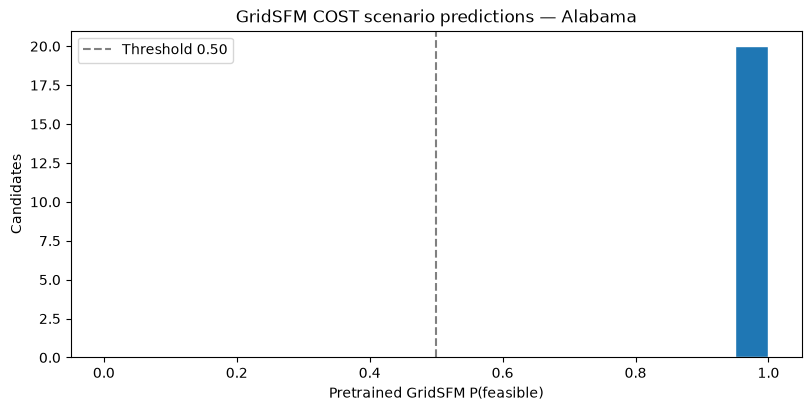

In [5]:
fig,ax=plt.subplots(figsize=(8,4),constrained_layout=True)
ax.hist(model_probs,bins=np.linspace(0,1,21),edgecolor="white")
ax.axvline(MODEL_THRESHOLD,ls="--",color="gray",label=f"Threshold {MODEL_THRESHOLD:.2f}")
ax.set(xlabel="Pretrained GridSFM P(feasible)",ylabel="Candidates",
       title=f"GridSFM COST scenario predictions — {DATASET_LABEL}")
ax.legend()
fig.savefig(EXPLAIN_ROOT/"model_feasibility_histogram.png",dpi=180,bbox_inches="tight")
plt.show()


## 5. Choose a candidate by the **pretrained model** prediction


In [6]:
FILTERS=["All candidates","Predicted feasible","Predicted infeasible",
         "High confidence feasible (P>=0.9)","High confidence infeasible (P<=0.1)",
         "Near threshold (0.4<=P<=0.6)","Largest total cost change"]

def matching_rows(category):
    if category=="Predicted feasible":return [r for r in model_rows if r["model_prediction"]=="Feasible"]
    if category=="Predicted infeasible":return [r for r in model_rows if r["model_prediction"]=="Infeasible"]
    if category=="High confidence feasible (P>=0.9)":return [r for r in model_rows if r["model_p_feasible"]>=.9]
    if category=="High confidence infeasible (P<=0.1)":return [r for r in model_rows if r["model_p_feasible"]<=.1]
    if category=="Near threshold (0.4<=P<=0.6)":return [r for r in model_rows if .4<=r["model_p_feasible"]<=.6]
    if category=="Largest total cost change":
        return sorted(model_rows,key=lambda r:np.sum(np.abs(candidates[r["index"]]-original_cp)),reverse=True)[:25]
    return model_rows

def row_label(r):
    return f'#{r["index"]:03d} | iter {r["iteration"]}, s{r["scenario"]} | {r["model_prediction"]} | P={r["model_p_feasible"]:.4f}'

WIDGETS_AVAILABLE=False
CANDIDATE_WIDGET=None
FILTER_WIDGET=None
try:
    import ipywidgets as widgets
    from IPython.display import display
    FILTER_WIDGET=widgets.Dropdown(options=FILTERS,value=FILTERS[0],description="Show:",layout=widgets.Layout(width="390px"))
    CANDIDATE_WIDGET=widgets.Dropdown(description="Candidate:",layout=widgets.Layout(width="640px"))
    def refresh_candidates(change=None):
        matches=matching_rows(FILTER_WIDGET.value)
        CANDIDATE_WIDGET.options=[(row_label(r),int(r["index"])) for r in matches]
        if not matches:print("No candidate matches this filter. Select another category.")
    FILTER_WIDGET.observe(refresh_candidates,names="value")
    refresh_candidates()
    display(FILTER_WIDGET,CANDIDATE_WIDGET)
    WIDGETS_AVAILABLE=True
except (ImportError,RuntimeError,Exception) as exc:
    print("Candidate dropdown unavailable — edit MANUAL_SCENARIO_INDEX in the next cell:",exc)

print("First 10 candidates:")
for r in model_rows[:10]:print(row_label(r))


Candidate dropdown unavailable — edit MANUAL_SCENARIO_INDEX in the next cell: No module named 'ipywidgets'
First 10 candidates:
#000 | iter 1, s1 | Feasible | P=0.9999
#001 | iter 1, s2 | Feasible | P=0.9999
#002 | iter 2, s1 | Feasible | P=0.9999
#003 | iter 2, s2 | Feasible | P=0.9999
#004 | iter 3, s1 | Feasible | P=0.9999
#005 | iter 3, s2 | Feasible | P=0.9999
#006 | iter 4, s1 | Feasible | P=0.9999
#007 | iter 4, s2 | Feasible | P=0.9999
#008 | iter 5, s1 | Feasible | P=0.9999
#009 | iter 5, s2 | Feasible | P=0.9999


## 6. Activate selected scenario and SHAP target class


In [7]:
MANUAL_SCENARIO_INDEX=0
EXPLANATION_TARGET="predicted"  # "predicted", "feasible", "infeasible"
assert EXPLANATION_TARGET in ("predicted","feasible","infeasible")
if WIDGETS_AVAILABLE:
    if CANDIDATE_WIDGET.value is None:
        raise ValueError("No candidates in the current filter; select another category")
    selected_index=int(CANDIDATE_WIDGET.value)
else:
    selected_index=int(MANUAL_SCENARIO_INDEX)
if not 0<=selected_index<len(candidates):
    raise IndexError(f"Candidate index {selected_index} out of range 0..{len(candidates)-1}")
chosen=candidates[selected_index].copy()
selected_rows=np.flatnonzero(selected_mask[selected_index])
selected_ids=[gen_ids[i] for i in selected_rows]
selected_p=float(model_probs[selected_index])
TARGET_CLASS=("feasible" if selected_p>=MODEL_THRESHOLD else "infeasible") if EXPLANATION_TARGET=="predicted" else EXPLANATION_TARGET

def target_score(costs):
    p=model_p_feasible(costs)
    return p if TARGET_CLASS=="feasible" else (1-p)

print("Selected:",row_label(model_rows[selected_index]))
print("Changed generator IDs:",selected_ids)
print("Explain class:",TARGET_CLASS)
print("Baseline target P:",target_score(original_cp),"| selected target P:",target_score(chosen))
EXPLAIN_DIR=EXPLAIN_ROOT/f"candidate_{selected_index:04d}"
EXPLAIN_DIR.mkdir(parents=True,exist_ok=True)


Selected: #000 | iter 1, s1 | Feasible | P=0.9999
Changed generator IDs: [np.str_('2'), np.str_('34'), np.str_('6'), np.str_('4'), np.str_('3'), np.str_('57')]
Explain class: feasible
Baseline target P: 0.9999414682388306 | selected target P: 0.9999467134475708


## 7. See the original and sampled generator cost coefficients


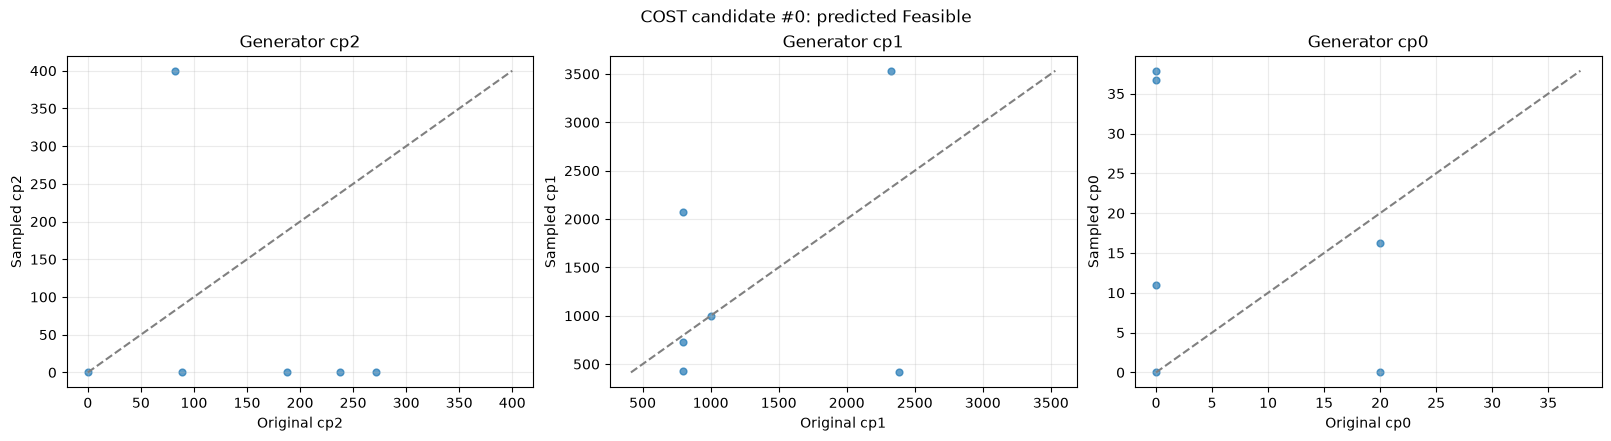

In [8]:
fig,axes=plt.subplots(1,3,figsize=(16,4.3),constrained_layout=True)
for j,name in enumerate(("cp2","cp1","cp0")):
    orig=original_cp[selected_rows,j];new=chosen[selected_rows,j]
    axes[j].scatter(orig,new,s=24,alpha=.7)
    lo=float(min(orig.min(),new.min()));hi=float(max(orig.max(),new.max()))
    if hi<=lo:hi=lo+1
    axes[j].plot([lo,hi],[lo,hi],color="gray",ls="--")
    axes[j].set(xlabel=f"Original {name}",ylabel=f"Sampled {name}",title=f"Generator {name}")
    axes[j].grid(alpha=.25)
fig.suptitle(f"COST candidate #{selected_index}: predicted {model_rows[selected_index]['model_prediction']}")
fig.savefig(EXPLAIN_DIR/"original_vs_sampled_costs.png",dpi=180,bbox_inches="tight")
plt.show()


## 8. Group Kernel SHAP over **all selected generators**

Each SHAP feature is a group of changed **generator IDs**. Switching a group on means applying all their sampled cost coefficients; switching it off means retaining original costs. All other components stay unchanged. The reference is the original grid. For more reliable estimates increase `N_GROUP_SHAP_SAMPLES`.


In [9]:
N_GROUPS=min(10,len(selected_rows))
N_GROUP_SHAP_SAMPLES=256 # Try 512/1024 for more stable ranking
assert N_GROUPS>=1
ordered_positions=np.arange(len(selected_rows))
position_groups=np.array_split(ordered_positions,N_GROUPS)
group_generator_rows=[selected_rows[pos] for pos in position_groups]
group_info=[]
for gi,rows in enumerate(group_generator_rows):
    group_info.append({"group":gi+1,"generator_ids":",".join(gen_ids[j] for j in rows),"n_generators":len(rows)})

def forward_group_masks(masks):
    binary=torch.as_tensor(masks).detach().cpu().numpy().reshape(-1,N_GROUPS)
    result=[]
    for bits in binary:
        candidate=original_cp.copy()
        for gi,rows in enumerate(group_generator_rows):
            if bits[gi]>=0.5:candidate[rows]=chosen[rows]
        result.append(target_score(candidate))
    return torch.tensor(result,dtype=torch.float32)

shap_group=KernelShap(forward_group_masks).attribute(
    torch.ones(1,N_GROUPS),baselines=torch.zeros(1,N_GROUPS),
    n_samples=N_GROUP_SHAP_SAMPLES,perturbations_per_eval=1,
    show_progress=False).detach().cpu().numpy().reshape(-1)
base_target=target_score(original_cp)
chosen_target=target_score(chosen)
print("GridSFM target probability change:",chosen_target-base_target)
print("Sum of approximate group SHAP:",float(shap_group.sum()))
print("Approximation residual:",(chosen_target-base_target)-float(shap_group.sum()))
for gi,s in enumerate(shap_group):group_info[gi]["shap_contribution"]=float(s)


GridSFM target probability change: 5.245208740234375e-06
Sum of approximate group SHAP: 5.24524193679099e-06
Approximation residual: -3.319655661471188e-11


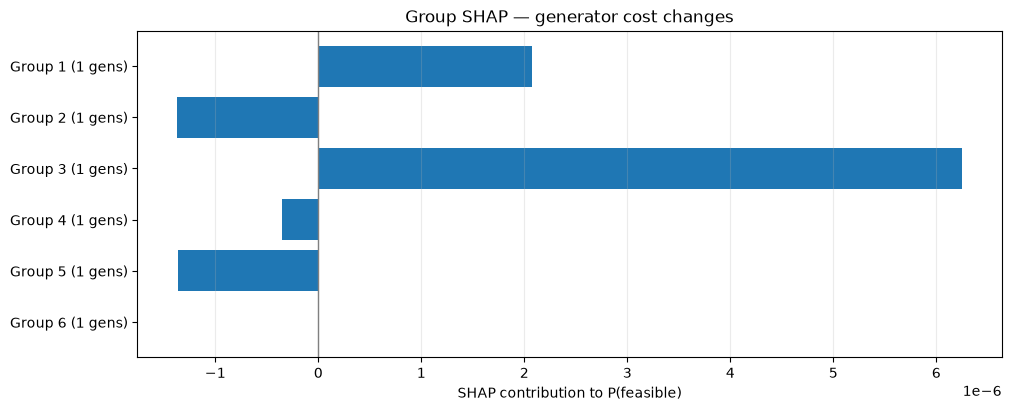

In [10]:
fig,ax=plt.subplots(figsize=(10,max(4,N_GROUPS*.45+1)),constrained_layout=True)
ys=np.arange(N_GROUPS)
ax.barh(ys,shap_group)
ax.set_yticks(ys,[f"Group {g+1} ({group_info[g]['n_generators']} gens)" for g in ys])
ax.axvline(0,color="gray",lw=1)
ax.set(xlabel=f"SHAP contribution to P({TARGET_CLASS})",title="Group SHAP — generator cost changes")
ax.invert_yaxis();ax.grid(axis="x",alpha=.25)
fig.savefig(EXPLAIN_DIR/"generator_group_shap.png",dpi=180,bbox_inches="tight")
plt.show()


## 9. Focused generator-and-coefficient SHAP

Choose changed generator IDs manually (`MANUAL_GENERATOR_IDS`) or use the top SHAP groups. Up to `MAX_COEFFICIENT_FEATURES` individual coefficient changes are explained. This explanation is **conditional**: all other changes in the candidate stay applied, while the focused coefficients are toggled between original and sampled values.


In [11]:
MANUAL_GENERATOR_IDS=None   # e.g., ["12","34"] — must be selected in this scenario
TOP_SHAP_GROUPS=2
MAX_COEFFICIENT_FEATURES=9
N_COEFFICIENT_SHAP_SAMPLES=256
if MANUAL_GENERATOR_IDS is not None:
    focus_ids=list(dict.fromkeys(str(x) for x in MANUAL_GENERATOR_IDS))
    if not focus_ids or any(gid not in selected_ids for gid in focus_ids):
        raise ValueError("MANUAL_GENERATOR_IDS must contain only changed generator IDs")
else:
    leaders=np.argsort(-np.abs(shap_group))[:TOP_SHAP_GROUPS]
    focus_rows=[int(i) for g in leaders for i in group_generator_rows[g]]
    focus_ids=[gen_ids[i] for i in focus_rows]

# Each one is (generator row, cost-channel index).
features=[]
for gid in focus_ids:
    row=int(np.flatnonzero(gen_ids==gid)[0]) if isinstance(gen_ids,np.ndarray) else gen_ids.index(gid)
    for j in (0,1,2):
        if cost_family[row]=="linear" and j==0:continue
        if abs(chosen[row,j]-original_cp[row,j])>1e-12:
            features.append((row,j))
features=sorted(features,key=lambda t:abs(chosen[t]-original_cp[t]),reverse=True)[:MAX_COEFFICIENT_FEATURES]
if not features:
    print("All selected cost coefficients equal their baseline values; SHAP coefficients are zero.")
    coefficient_shap=np.empty(0)
else:
    n_features=len(features)
    conditional_baseline=chosen.copy()
    for r,j in features:conditional_baseline[r,j]=original_cp[r,j]
    def forward_coefficient_masks(masks):
        binary=torch.as_tensor(masks).detach().cpu().numpy().reshape(-1,n_features)
        out=[]
        for bits in binary:
            patch=conditional_baseline.copy()
            for k,(r,j) in enumerate(features):
                if bits[k]>=0.5:patch[r,j]=chosen[r,j]
            out.append(target_score(patch))
        return torch.tensor(out,dtype=torch.float32)
    coefficient_shap=KernelShap(forward_coefficient_masks).attribute(
        torch.ones(1,n_features),baselines=torch.zeros(1,n_features),
        n_samples=N_COEFFICIENT_SHAP_SAMPLES,perturbations_per_eval=1,
        show_progress=False).detach().cpu().numpy().reshape(-1)
coefficient_rows=[]
for (r,j),score in zip(features,coefficient_shap):
    gid=str(gen_ids[r]); g=data["gen"][gid]
    bus_id=str(g.get("gen_bus",""))
    coefficient_rows.append(dict(generator_id=gid,bus_id=bus_id,
        bus_name=str(data.get("bus",{}).get(bus_id,{}).get("name","")),
        cost_family=str(cost_family[r]),coefficient=("cp2","cp1","cp0")[j],
        original=float(original_cp[r,j]),sampled=float(chosen[r,j]),
        delta=float(chosen[r,j]-original_cp[r,j]),
        shap_contribution=float(score),target_class=TARGET_CLASS))
coefficient_rows=sorted(coefficient_rows,key=lambda row:abs(row["shap_contribution"]),reverse=True)
print("Focused coefficients:",len(coefficient_rows))
for r in coefficient_rows:print(r)


Focused coefficients: 6
{'generator_id': '6', 'bus_id': '9', 'bus_name': 'Barry Substation', 'cost_family': 'quadratic', 'coefficient': 'cp2', 'original': 238.06848000000005, 'sampled': 0.0, 'delta': -238.06848000000005, 'shap_contribution': 4.1106200114882085e-06, 'target_class': 'feasible'}
{'generator_id': '6', 'bus_id': '9', 'bus_name': 'Barry Substation', 'cost_family': 'quadratic', 'coefficient': 'cp1', 'original': 2381.0, 'sampled': 414.3069953894651, 'delta': -1966.693004610535, 'shap_contribution': 1.713193910291011e-06, 'target_class': 'feasible'}
{'generator_id': '2', 'bus_id': '238', 'bus_name': 'E B Harris Electric Generating Plant', 'cost_family': 'quadratic', 'coefficient': 'cp2', 'original': 82.60459574468084, 'sampled': 399.96959835760396, 'delta': 317.36500261292315, 'shap_contribution': 1.2404917697494966e-06, 'target_class': 'feasible'}
{'generator_id': '2', 'bus_id': '238', 'bus_name': 'E B Harris Electric Generating Plant', 'cost_family': 'quadratic', 'coefficient

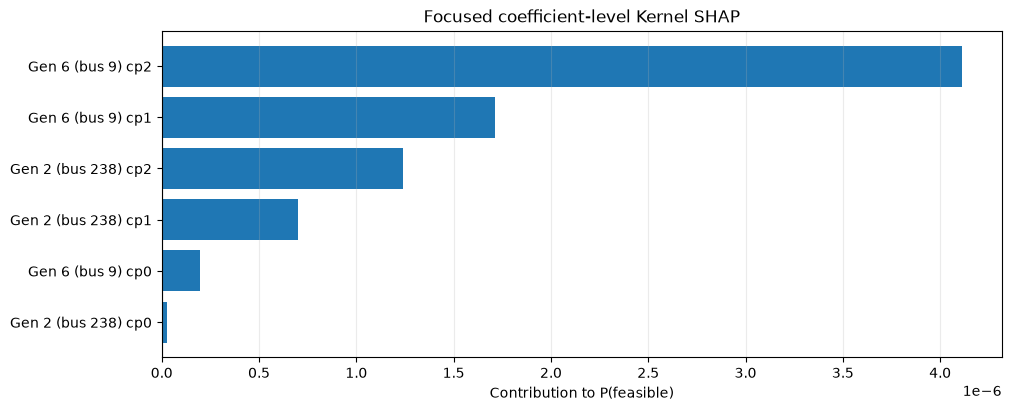

In [12]:
if coefficient_rows:
    fig,ax=plt.subplots(figsize=(10,max(4,len(coefficient_rows)*.44+1)),constrained_layout=True)
    vals=[r["shap_contribution"] for r in coefficient_rows]
    labels=[f"Gen {r['generator_id']} (bus {r['bus_id']}) {r['coefficient']}" for r in coefficient_rows]
    y=np.arange(len(vals))
    ax.barh(y,vals);ax.set_yticks(y,labels);ax.invert_yaxis()
    ax.axvline(0,color="gray")
    ax.set(xlabel=f"Contribution to P({TARGET_CLASS})",title="Focused coefficient-level Kernel SHAP")
    ax.grid(axis="x",alpha=.25)
    fig.savefig(EXPLAIN_DIR/"generator_coefficient_shap.png",dpi=180,bbox_inches="tight")
    plt.show()


## 10. Export predictions, group and coefficient SHAP


In [13]:
def write_csv(path,rows):
    if not rows:return
    with Path(path).open("w",newline="",encoding="utf-8") as f:
        w=csv.DictWriter(f,fieldnames=list(rows[0]))
        w.writeheader();w.writerows(rows)

write_csv(EXPLAIN_ROOT/"pretrained_model_predictions.csv",model_rows)
write_csv(EXPLAIN_DIR/"group_shap.csv",group_info)
write_csv(EXPLAIN_DIR/"coefficient_shap.csv",coefficient_rows)
summary={"dataset":DATASET_NAME,"candidate_index":selected_index,
    "model_p_feasible":selected_p,"model_predicted_class":model_rows[selected_index]["model_prediction"],
    "explanation_target":TARGET_CLASS,"p_original":p_original,
    "selected_generator_ids":selected_ids,"group_shap_sum":float(shap_group.sum()),
    "group_shap_residual":float((chosen_target-base_target)-shap_group.sum()),
    "checkpoint":str(CHECKPOINT_PATH),"pyg_graph":str(PYG_PATH)}
with (EXPLAIN_DIR/"explanation_summary.json").open("w",encoding="utf-8") as f:
    json.dump(summary,f,indent=2)
print("Predictions:",EXPLAIN_ROOT/"pretrained_model_predictions.csv")
print("Candidate explanation:",EXPLAIN_DIR)


Predictions: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama/gridsfm_pretrained_cost_shap/pretrained_model_predictions.csv
Candidate explanation: /Users/punrong_rany/Desktop/Projects/GridSFM/results/gaussian_cost/alabama/gridsfm_pretrained_cost_shap/candidate_0000


## Interpretation and limitations

- **Julia** guided the sampling in Notebook 1. **Pretrained GridSFM** provides the feasible/infeasible prediction here. **SHAP** explains *GridSFM's prediction*, not Julia's AC-OPF output.
- Positive SHAP values increase the target probability shown (`P(feasible)` or `P(infeasible)`); negative values reduce it. `EXPLANATION_TARGET="predicted"` chooses the class predicted by GridSFM.
- Group SHAP toggles generator cost vectors from original to sampled. Focused coefficient SHAP is conditional on other changed costs remaining at their sampled values. They are **different attribution games**; do not add them together.
- The model receives canonical raw generator columns `cp2`, `cp1`, `cp0`. This notebook refuses missing `gen_id_map` or mismatched raw/PyG costs rather than silently attributing wrong generators.
- **Physical caveat:** Modifying generator costs generally changes the AC-OPF objective and optimum dispatch, but not the feasible set. Therefore feasibility predictions may barely move, and SHAP scores may be near zero. Such results are not necessarily a bug. To study cost effects more directly, explain a model output such as predicted `Pg` or a derived economic dispatch cost instead.
- Captum Kernel SHAP uses approximate sampling for larger feature sets; compare repeated runs and increase `N_GROUP_SHAP_SAMPLES` / `N_COEFFICIENT_SHAP_SAMPLES` for more reliable generator rankings.
- Model feasibility probabilities are predictions, not calibrated guarantees or solver certificates.

**References:** `https://github.com/microsoft/GridSFM/blob/main/model/README.md` for PyG generator feature columns; `https://github.com/microsoft/GridSFM/blob/main/power_grid/US/topology_solver_pipeline/PIPELINE_DETAILS.md` for cost perturbation context.
